# Proyecto de Aplicación
## Pontifica Universidad Javeriana
## Especialización en IA

## Prompt Solution Client
## Grupo 6 - Agent Fintech

* Daniel Oviedo

* Julian Olaya

* Juan Pablo Rivera

* Wilmar Roa

## Fase 1: Comprensión del Negocio y Configuración Inicial

In [28]:
# 1. Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual
sns.set_theme(style="whitegrid")
%matplotlib inline

# 2. Cargar el dataset consolidado
df = pd.read_csv('dataset_medios_pago_sintetico.csv')
print(f"Dataset cargado con éxito: {df.shape[0]} filas y {df.shape[1]} columnas.")

Dataset cargado con éxito: 5000 filas y 21 columnas.


In [29]:
df.head()

,tx_id,timestamp,user_id,user_avg_ticket_size,user_cashback_responsiveness,user_credit_limit_utilization,user_balance_account_ratio,merchant_id,merchant_name,mcc_code,...,merchant_avg_ticket_size,merchant_accepts_installment,merchant_tx_volume_30d,tx_amount,tx_hour,tx_day_of_week,tx_channel,is_payroll_day,incentive_active_flag,target_chosen_payment_method
0,TX-100000,2026-01-05 20:51:00,USR-1275,93900.0,0.64,0.09,7.55,MERCH-537,Rodríguez-Camargo - Restaurantes,5812,...,42500.0,False,1624,49900.0,20,0,QR_DYNAMIC,False,True,DIRECT_ACCOUNT_TRANSFER
1,TX-100001,2026-05-15 11:15:00,USR-1471,259400.0,0.76,0.18,1.94,MERCH-513,Caicedo Ltd - Estaciones de Servicio,5541,...,90100.0,False,2085,85700.0,11,4,E_COMMERCE_GATEWAY,True,False,CREDIT_CARD_BANK
2,TX-100002,2026-03-10 19:05:00,USR-1418,169700.0,0.17,0.87,3.30,MERCH-546,Mantilla PLC - Farmacias,5912,...,34600.0,False,2031,42400.0,19,1,POS_PHYSICAL,False,False,DEBIT_CARD
3,TX-100003,2026-03-04 14:19:00,USR-1236,39900.0,0.78,0.35,5.63,MERCH-573,Salazar-Yepes - Restaurantes,5812,...,42000.0,False,473,64400.0,14,2,QR_STATIC,False,True,DIRECT_ACCOUNT_TRANSFER
4,TX-100004,2026-04-08 19:35:00,USR-1048,210600.0,0.50,0.74,4.07,MERCH-552,Torres LLC - Farmacias,5912,...,28600.0,False,548,26300.0,19,2,QR_STATIC,False,False,CREDIT_CARD_BANK


## Fase 2: Comprensión de los Datos (Data Understanding & EDA)

In [30]:
# 1. Resumen estructural y tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   tx_id                          5000 non-null   object 
 1   timestamp                      5000 non-null   object 
 2   user_id                        5000 non-null   object 
 3   user_avg_ticket_size           5000 non-null   float64
 4   user_cashback_responsiveness   5000 non-null   float64
 5   user_credit_limit_utilization  5000 non-null   float64
 6   user_balance_account_ratio     5000 non-null   float64
 7   merchant_id                    5000 non-null   object 
 8   merchant_name                  5000 non-null   object 
 9   mcc_code                       5000 non-null   int64  
 10  mcc_category                   5000 non-null   object 
 11  merchant_avg_ticket_size       5000 non-null   float64
 12  merchant_accepts_installment   5000 non-null   b

/tmp/ipykernel_2599/988493413.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='target_chosen_payment_method', palette='viridis')


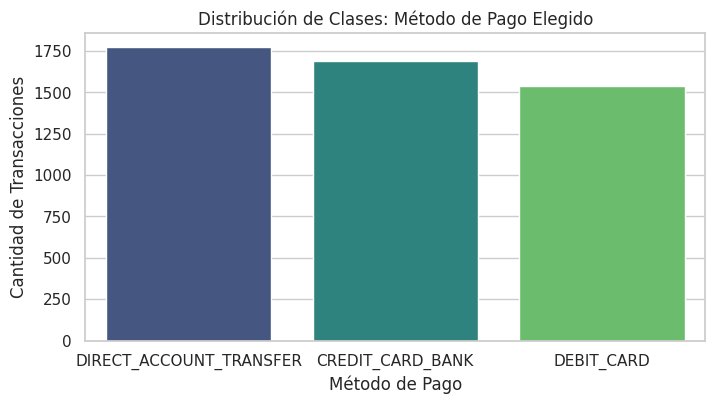

In [31]:
# 2. Distribución de la variable objetivo (Target Balance)
plt.figure(figsize=(8, 4))
ax = sns.countplot(data=df, x='target_chosen_payment_method', palette='viridis')
plt.title('Distribución de Clases: Método de Pago Elegido')
plt.ylabel('Cantidad de Transacciones')
plt.xlabel('Método de Pago')
plt.show()

/tmp/ipykernel_2599/3734559181.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='mcc_category', y='tx_amount', palette='Set2')


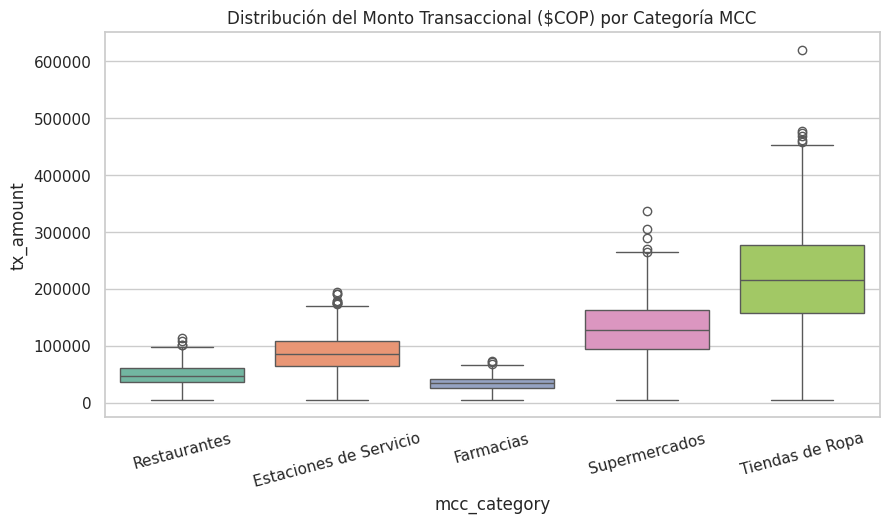

In [32]:
# 3. Análisis de Montos por Categoría
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='mcc_category', y='tx_amount', palette='Set2')
plt.title('Distribución del Monto Transaccional ($COP) por Categoría MCC')
plt.xticks(rotation=15)
plt.show()

### **Descripción de Variables**

**1.** Identificadores y Contexto Transaccional (No predictors / Metadata):

`tx_id`: Identificador único de la transacción (llave primaria)

`timestamp`: Fecha y hora exacta del evento

`user_id`: Identificador anonimizado del cliente

`merchant_id` / `merchant_name`: Identificador y nombre del establecimiento


**2.** Variables del Perfil de Usuario (Customer Features)

`user_avg_ticket_size`: Ticket promedio de compra histórico del usuario ($COP$)

`user_cashback_responsiveness`: Sensibilidad o propensión histórica al ahorro/cashback ($0.0$ a $1.0$)

`user_credit_limit_utilization`: Porcentaje de uso actual de la tarjeta de crédito ($0.0$ a $1.0$)

`user_balance_account_ratio`: Coeficiente de liquidez actual ($\text{Saldo en cuenta} / \text{Monto de compra}$).

**3.** Variables del Comercio y Entorno (Merchant & Context Features):

`mcc_code` / `mcc_category`: Código estándar y categoría del negocio (Restaurantes, Supermercados, etc.)

`merchant_avg_ticket_size`: Ticket promedio habitual que se factura en el comercio

`merchant_accepts_installment`: Flag booleano (True/False) de si el comercio permite diferir a cuotas

`merchant_tx_volume_30d`: Volumen transaccional del comercio en los últimos 30 días (popularidad/confianza)

`tx_amount`: Monto total cobrado en la caja o QR ($COP$)

`tx_hour`: Hora del día ($0$ a $23$)

`tx_day_of_week`: Día de la semana ($0 = \text{Lunes}$, $6 = \text{Domingo}$)

`tx_channel`: Canal de cobro (QR_DYNAMIC, QR_STATIC, POS_PHYSICAL, E_COMMERCE_GATEWAY)

`is_payroll_day`: Flag booleano que indica si la transacción ocurre en días de pago de nómina/quincena

`incentive_active_flag`: Flag booleano que indica si existe convenio o beneficio activo en esa categoría

**4.** Variable Objetivo (Target Label)

`target_chosen_payment_method`: Clase a predecir por el algoritmo:   DIRECT_ACCOUNT_TRANSFER (Transferencia por QR / Ahorros)   CREDIT_CARD_BANK (Tarjeta de Crédito)   DEBIT_CARD (Tarjeta Débito)  

## Fase 3: Preparación de los Datos (Data Preparation & Feature Engineering)

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# 1. Separar identificadores, predictores y variable objetivo
ignore_cols = ['tx_id', 'timestamp', 'user_id', 'merchant_id', 'merchant_name', 'target_chosen_payment_method']
X = df.drop(columns=ignore_cols)
y = df['target_chosen_payment_method']

# 2. Definir columnas por tipo de transformación
categorical_cols = ['mcc_category', 'tx_channel']
numeric_cols = [
    'user_avg_ticket_size', 'user_cashback_responsiveness',
    'user_credit_limit_utilization', 'user_balance_account_ratio',
    'mcc_code', 'merchant_avg_ticket_size', 'merchant_tx_volume_30d',
    'tx_amount', 'tx_hour', 'tx_day_of_week'
]
bool_cols = ['merchant_accepts_installment', 'is_payroll_day', 'incentive_active_flag']

# 3. Pipeline de Preprocesamiento
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
        ('bool', 'passthrough', bool_cols)
    ]
)

# 4. División Train / Test (80% / 20%) con estratificación
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Set de Entrenamiento: {X_train.shape}")
print(f"Set de Evaluación: {X_test.shape}")

Set de Entrenamiento: (4000, 15)
Set de Evaluación: (1000, 15)


## Fase 4: Modelado (Modeling - XGBoost Multi-Class)

In [34]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline

# 1. Codificar etiquetas del Target (Strings -> Integers)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# 2. Definir el Pipeline con XGBoost
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=5,
        random_state=42,
        eval_metric='mlogloss'
    ))
])

# 3. Entrenar el modelo
model_pipeline.fit(X_train, y_train_encoded)
print("¡Modelo XGBoost entrenado exitosamente!")

¡Modelo XGBoost entrenado exitosamente!


## Fase 5: Evaluación del Modelo (Evaluation)

--- REPORTE DE CLASIFICACIÓN ---
                         precision    recall  f1-score   support

       CREDIT_CARD_BANK       0.83      0.69      0.75       337
             DEBIT_CARD       0.69      0.86      0.77       308
DIRECT_ACCOUNT_TRANSFER       0.79      0.75      0.77       355

               accuracy                           0.76      1000
              macro avg       0.77      0.77      0.76      1000
           weighted avg       0.77      0.76      0.76      1000

Área bajo la curva ROC (ROC-AUC Multi-Class): 0.9213


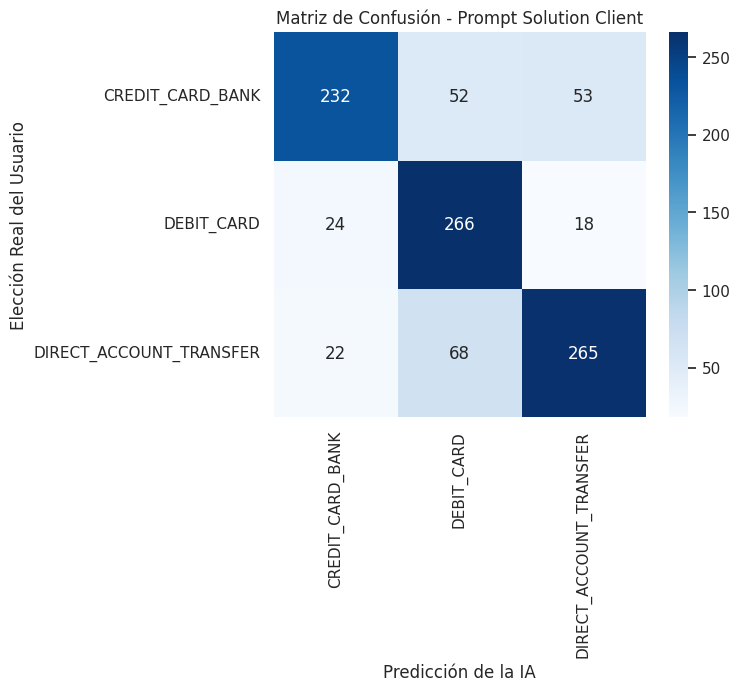

In [35]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# 1. Inferencia sobre el set de prueba
y_pred_encoded = model_pipeline.predict(X_test)
y_pred_proba = model_pipeline.predict_proba(X_test)

# 2. Métricas de desempeño
print("--- REPORTE DE CLASIFICACIÓN ---")
print(classification_report(y_test_encoded, y_pred_encoded, target_names=le.classes_))

# 3. ROC-AUC Multi-Clase
auc_score = roc_auc_score(y_test_encoded, y_pred_proba, multi_class='ovr')
print(f"Área bajo la curva ROC (ROC-AUC Multi-Class): {auc_score:.4f}")

# 4. Matriz de Confusión
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion_matrix(y_test_encoded, y_pred_encoded),
    annot=True, fmt='d', cmap='Blues',
    xticklabels=le.classes_, yticklabels=le.classes_
)
plt.title('Matriz de Confusión - Prompt Solution Client')
plt.xlabel('Predicción de la IA')
plt.ylabel('Elección Real del Usuario')
plt.show()

## Fase 6: Despliegue (Deployment / Exportación del Artefacto)

In [36]:
import joblib

# Exportar el pipeline completo y el codificador de etiquetas
joblib.dump(model_pipeline, 'model_payment_final.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("✅ Artefactos '.pkl' exportados.")

✅ Artefactos '.pkl' exportados. Listos para ser consumidos por la API REST en FastAPI.
